#**Importing the necessary libraries and loading the dataset for analysis.**

In [ ]:
import pandas as pd
# Charger les données
df = pd.read_csv("/content/sample_data/Data7.csv")
print(df.info())
print(df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Id                            312 non-null    int64  
 1   Country or region             312 non-null    object 
 2   Score                         312 non-null    float64
 3   GDP per capita                312 non-null    float64
 4   Social support                312 non-null    float64
 5   Healthy life expectancy       312 non-null    float64
 6   Freedom to make life choices  312 non-null    float64
 7   Generosity                    312 non-null    float64
 8   Perceptions of corruption     311 non-null    float64
dtypes: float64(7), int64(1), object(1)
memory usage: 22.1+ KB
None
(312, 9)




**This dataset,  provides a comparative look at subjective well-being across various countries or regions. The dataset evaluates several socio-economic and psychological indicators to assign an overall happiness score to each country. The following dimensions are included:**

- **Id**: a unique identifier for each country or region in the dataset  
- **Score**: the overall level of happiness reported by the population  
- **GDP per capita**: an indicator of average economic prosperity  
- **Social support**: the perceived level of support individuals receive from others  
- **Healthy life expectancy**: the expected number of years lived in good health  
- **Freedom to make life choices**: the perceived freedom to make important life decisions  
- **Generosity**: the willingness of individuals to help others and contribute to society  
- **Perceptions of corruption**: the level of trust in public institutions and government  

**Each row corresponds to a specific country or region, allowing for straightforward comparison of the key factors influencing happiness worldwide.**



#**Quick look at the dataset**

 Look at the mean, standard deviation, minimum, and maximum for the numerical columns.

In [ ]:
print(df.describe())

               Id       Score  GDP per capita  Social support  \
count  312.000000  312.000000      312.000000      312.000000   
mean    81.064103    5.391506        0.898298        1.211026   
std     46.382262    1.114631        0.394592        0.300310   
min      1.000000    2.853000        0.000000        0.000000   
25%     41.750000    4.514250        0.609500        1.055750   
50%     80.500000    5.379500        0.960000        1.265500   
75%    119.250000    6.176000        1.219500        1.457500   
max    204.000000    7.769000        2.096000        1.644000   

       Healthy life expectancy  Freedom to make life choices  Generosity  \
count               312.000000                    312.000000  312.000000   
mean                  0.661295                      0.423538    0.182926   
std                   0.252724                      0.156024    0.096739   
min                   0.000000                      0.000000    0.000000   
25%                   0.488250    

 Check the data types.

In [ ]:
print(df.dtypes)

Id                                int64
Country or region                object
Score                           float64
GDP per capita                  float64
Social support                  float64
Healthy life expectancy         float64
Freedom to make life choices    float64
Generosity                      float64
Perceptions of corruption       float64
dtype: object


 Check for missing values

In [ ]:
print(df.isnull().sum())

Id                              0
Country or region               0
Score                           0
GDP per capita                  0
Social support                  0
Healthy life expectancy         0
Freedom to make life choices    0
Generosity                      0
Perceptions of corruption       1
dtype: int64


 Quickly check the diversity of the data.

In [ ]:
print(df.sample(5))

      Id Country or region  Score  GDP per capita  Social support  \
96    97          Bulgaria  5.011           1.092           1.513   
301  146          Botswana  3.590           1.017           1.174   
213   58   Northern Cyprus  5.835           1.229           1.211   
284  129           Armenia  4.321           0.816           0.990   
144  145           Burundi  3.775           0.046           0.447   

     Healthy life expectancy  Freedom to make life choices  Generosity  \
96                     0.815                         0.311       0.081   
301                    0.417                         0.557       0.042   
213                    0.909                         0.495       0.179   
284                    0.666                         0.260       0.077   
144                    0.380                         0.220       0.176   

     Perceptions of corruption  
96                       0.004  
301                      0.092  
213                      0.154  
284     

 Detect duplicates (completely identical rows).

In [ ]:
print(df.duplicated().sum())

0


Check for duplicates based on IDs only.

In [ ]:
df['Id'].duplicated().sum()

np.int64(152)

 Check for duplicates based on country names only.

In [ ]:
df['Country or region'].duplicated().sum()

np.int64(152)

 Display all rows where the country name is duplicated (appears at least twice).

In [ ]:
df[df['Country or region'].duplicated(keep=False)]


,Id,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298
...,...,...,...,...,...,...,...,...,...
307,152,Yemen,3.355,0.442,1.073,0.343,0.244,0.083,0.064
308,153,Tanzania,3.303,0.455,0.991,0.381,0.481,0.270,0.097
309,154,South Sudan,3.254,0.337,0.608,0.177,0.112,0.224,0.106
310,155,Central African Republic,3.083,0.024,0.000,0.010,0.305,0.218,0.038


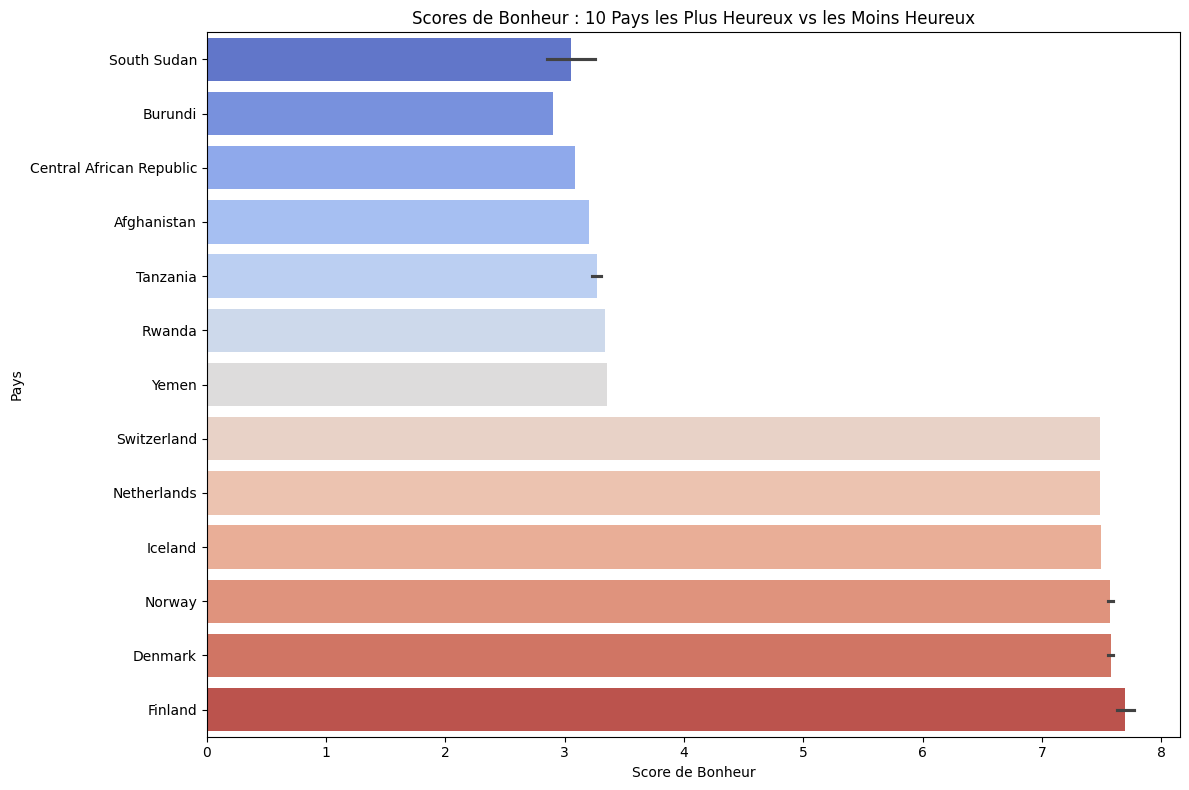

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Étape 1 : Trier par Score décroissant
df_sorted = df.sort_values(by="Score", ascending=False)

# Étape 2 : Sélectionner les 10 pays les plus heureux et les 10 moins heureux
top10 = df_sorted.head(10)
bottom10 = df_sorted.tail(10)

# Étape 3 : Combiner et trier pour affichage
combined_sorted = pd.concat([top10, bottom10])
combined_sorted = combined_sorted.sort_values(by="Score", ascending=True)

# Étape 4 : Barplot
plt.figure(figsize=(12, 8))
sns.barplot(
    x="Score",
    y="Country or region",
    data=combined_sorted,
    hue="Country or region",
    palette="coolwarm",
    legend=False
)
plt.title("Scores de Bonheur : 10 Pays les Plus Heureux vs les Moins Heureux")
plt.xlabel("Score de Bonheur")
plt.ylabel("Pays")
plt.tight_layout()
plt.show()

#**Data Processing**  
1) Replace a missing value (with the mean).

In [ ]:
mean_value = df['Perceptions of corruption'].mean()
df['Perceptions of corruption'].fillna(mean_value, inplace=True)

<ipython-input-11-4b73f26adbea>:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Perceptions of corruption'].fillna(mean_value, inplace=True)


**2)** Remove irrelevant columns.

In [ ]:
df=df.drop(columns=['Id','Country or region'])

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Score                         312 non-null    float64
 1   GDP per capita                312 non-null    float64
 2   Social support                312 non-null    float64
 3   Healthy life expectancy       312 non-null    float64
 4   Freedom to make life choices  312 non-null    float64
 5   Generosity                    312 non-null    float64
 6   Perceptions of corruption     312 non-null    float64
dtypes: float64(7)
memory usage: 17.2 KB
None


**3)** Sort the data.

In [ ]:
df = df.sort_values(by='Score',ascending=False)

4) Score ranges

**Score Ranges**  
Scores can be grouped as follows:

- **Low**: 0 – 5  
- **Medium**: 5 – 6.5  
- **High**: 6.5 – 8

In [ ]:
bins = [0, 5, 6.5, 8]
labels = ['LOW', 'MODIUM', 'HIGH']


Create the category column

In [ ]:
df['Score_Group'] = pd.cut(df['Score'], bins=bins, labels=labels, right=False)
df.head(40)
df.shape

(312, 8)

In [ ]:
#how to downoload the new dataset modified
df.to_csv('dataset_modifie.csv', index=False)
from google.colab import files
files.download('dataset_modifie.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Now my data is clean — duplicates have been removed, missing values handled, and the structure reorganized for better clarity.
Everything is set, so let’s move on to some simple data visualization.
We’ll start by creating a couple of histograms to explore the distribution of key variables.

#Data visualisation

In [ ]:
# Import libraries
import matplotlib.pyplot as plt
import seaborn as sns
df1 = pd.read_csv("/content/sample_data/dataset_modifie.csv")
print(df1.info())
print(df1.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 8 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Score                         312 non-null    float64
 1   GDP per capita                312 non-null    float64
 2   Social support                312 non-null    float64
 3   Healthy life expectancy       312 non-null    float64
 4   Freedom to make life choices  312 non-null    float64
 5   Generosity                    312 non-null    float64
 6   Perceptions of corruption     312 non-null    float64
 7   Score_Group                   312 non-null    object 
dtypes: float64(7), object(1)
memory usage: 19.6+ KB
None
(312, 8)


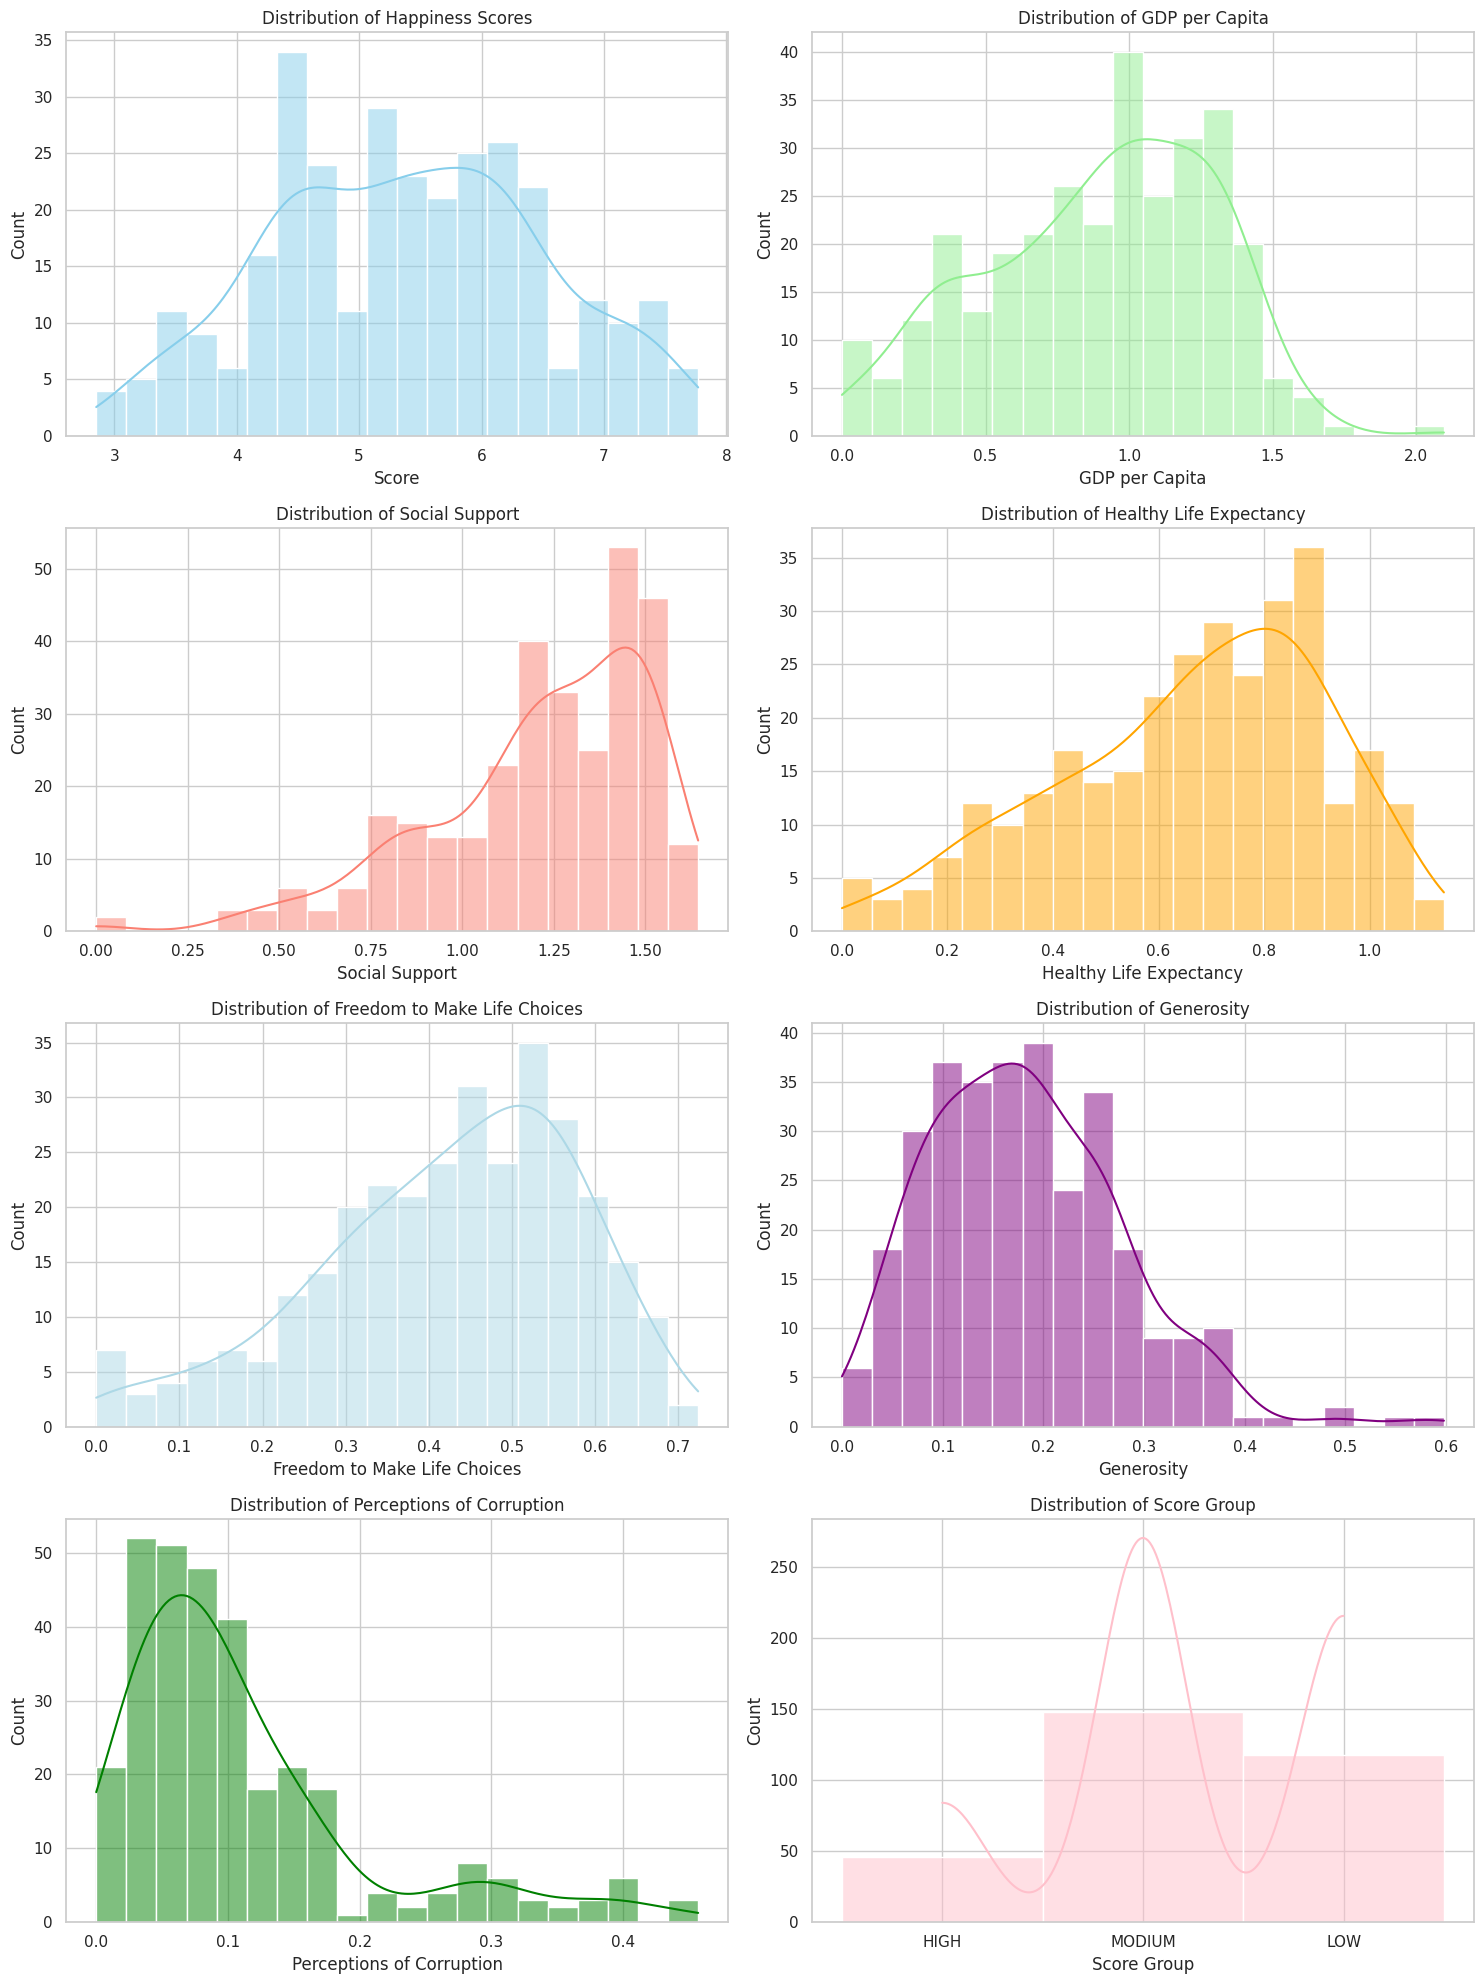

In [ ]:
# Set Seaborn style
sns.set(style="whitegrid")

# Create subplots for histograms (Now 4 rows, 2 columns to fit all 8 histograms)
fig, axes = plt.subplots(4, 2, figsize=(15, 20))  # 4 rows, 2 columns

# Histogram for Happiness Score
sns.histplot(df1['Score'], bins=20, kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Distribution of Happiness Scores')
axes[0, 0].set_xlabel('Score')

# Histogram for GDP per capita
sns.histplot(df1['GDP per capita'], bins=20, kde=True, ax=axes[0, 1], color='lightgreen')
axes[0, 1].set_title('Distribution of GDP per Capita')
axes[0, 1].set_xlabel('GDP per Capita')

# Histogram for Social Support
sns.histplot(df1['Social support'], bins=20, kde=True, ax=axes[1, 0], color='salmon')
axes[1, 0].set_title('Distribution of Social Support')
axes[1, 0].set_xlabel('Social Support')

# Histogram for Healthy Life Expectancy
sns.histplot(df1['Healthy life expectancy'], bins=20, kde=True, ax=axes[1, 1], color='orange')
axes[1, 1].set_title('Distribution of Healthy Life Expectancy')
axes[1, 1].set_xlabel('Healthy Life Expectancy')

# Histogram for Freedom to make life choices
sns.histplot(df1['Freedom to make life choices'], bins=20, kde=True, ax=axes[2, 0], color='lightblue')
axes[2, 0].set_title('Distribution of Freedom to Make Life Choices')
axes[2, 0].set_xlabel('Freedom to Make Life Choices')

# Histogram for Generosity
sns.histplot(df1['Generosity'], bins=20, kde=True, ax=axes[2, 1], color='purple')
axes[2, 1].set_title('Distribution of Generosity')
axes[2, 1].set_xlabel('Generosity')

# Histogram for Perceptions of corruption
sns.histplot(df1['Perceptions of corruption'], bins=20, kde=True, ax=axes[3, 0], color='green')
axes[3, 0].set_title('Distribution of Perceptions of Corruption')
axes[3, 0].set_xlabel('Perceptions of Corruption')

# Histogram for Score_Group
sns.histplot(df1['Score_Group'], bins=20, kde=True, ax=axes[3, 1], color='pink')
axes[3, 1].set_title('Distribution of Score Group')
axes[3, 1].set_xlabel('Score Group')

# Adjust the layout for better readability
plt.tight_layout()


Calculation of the correlation matrix (only for numeric variables)

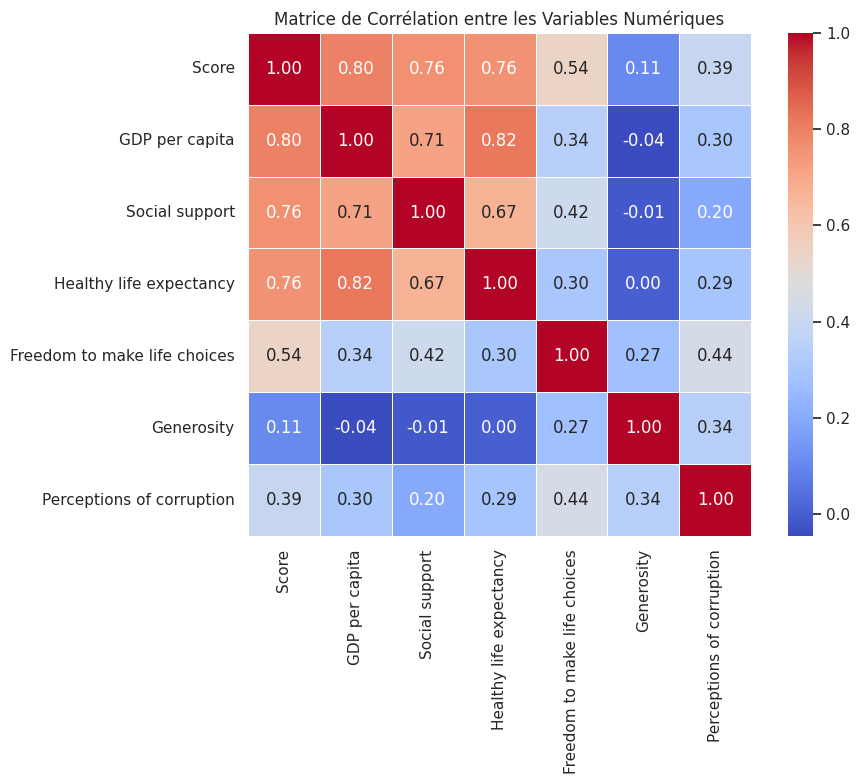

In [ ]:
correlation_matrix = df.corr(numeric_only=True)
# Affichage de la heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", square=True, linewidths=0.5)
plt.title("Matrice de Corrélation entre les Variables Numériques")
plt.tight_layout()
plt.show()


Correlations with Score

The best predictors of happiness in your dataset are:

* GDP per capita

* Healthy life expectancy

* Social support





# Regression
##Feature Engineering & Préparation des données
Objectives:

* Select the relevant variables

* Transform the variables if necessary (log, standardization, etc.)

* Encode categorical variables (OneHotEncoding, LabelEncoding)

* Manage outliers, if present

In [ ]:
# Feature Engineering & Data Preparation

# Select relevant variables
features = ['GDP per capita', 'Healthy life expectancy', 'Social support', 'Freedom to make life choices', 'Score']
df_selected = df1[features]

# Standardization (or normalization)
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
numerical_cols = ['GDP per capita', 'Healthy life expectancy', 'Social support', 'Freedom to make life choices']
df_selected[numerical_cols] = scaler.fit_transform(df_selected[numerical_cols])

# Outlier management (example: using IQR)
def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df = df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]
    return df

# Apply outlier removal (example for 'GDP per capita')
df_selected = remove_outliers_iqr(df_selected, 'GDP per capita')

# Display the preprocessed data
print(df_selected.head())

# Save the preprocessed dataset
df_selected.to_csv('preprocessed_dataset.csv', index=False)
from google.colab import files
files.download('preprocessed_dataset.csv')

   GDP per capita  Healthy life expectancy  Social support  \
0        1.121186                 1.286885        1.253965   
1        1.032345                 0.843002        1.270641   
2        1.230335                 1.326517        1.207272   
3        1.415633                 0.791480        1.237289   
4        1.149108                 0.819222        1.263971   

   Freedom to make life choices  Score  
0                      1.107129  7.769  
1                      1.652793  7.632  
2                      1.081451  7.600  
3                      1.684891  7.594  
4                      1.665632  7.555  


<ipython-input-20-09b4470b5250>:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_selected[numerical_cols] = scaler.fit_transform(df_selected[numerical_cols])


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Split + Régression linéaire

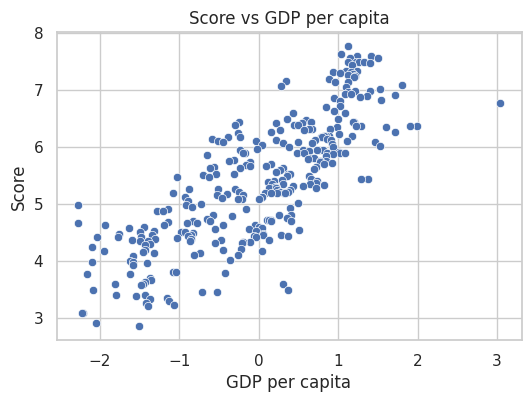

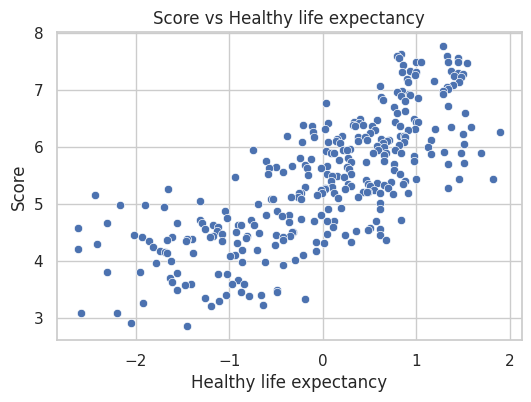

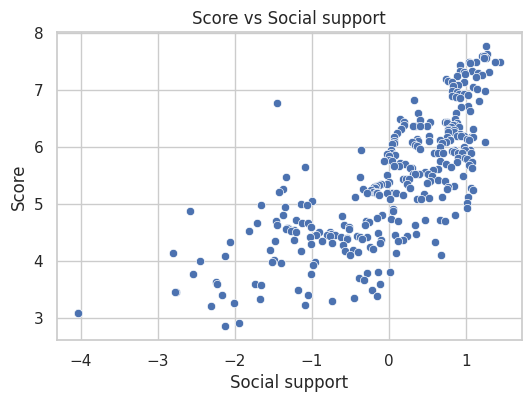

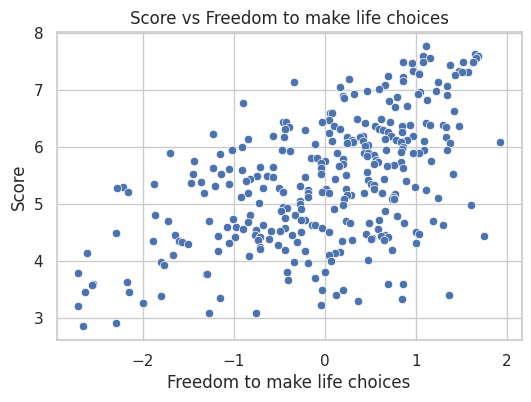

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Liste des features (ajout de 'Freedom to make life choices')
features = ['GDP per capita', 'Healthy life expectancy', 'Social support', 'Freedom to make life choices']

# Tracer chaque feature vs la cible
for feature in features:
    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=df_selected, x=feature, y='Score')
    plt.title(f'Score vs {feature}')
    plt.xlabel(feature)
    plt.ylabel('Score')
    plt.grid(True)
    plt.show()


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd

# Charger les données
df3 = pd.read_csv("/content/sample_data/preprocessed_dataset.csv")

# 1. Séparer X et y
X = df3.drop(columns=["Score"])
y = df3["Score"]

# 2. Split en jeu d'entraînement et de test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Entraîner un modèle de régression
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Prédictions
y_pred = model.predict(X_test)

# 5. Évaluation
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error (MSE):", mse)
# print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)
print(coefficients)

Mean Squared Error (MSE): 0.31685877927728756
R2 Score: 0.7417196808655444


#Régression linéaire multiple

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Créer un DataFrame avec transformations log(x + 1)
df_transformed = df_cleaned.copy()
cols_to_transform = ["Perceptions of corruption", "Generosity"]

for col in cols_to_transform:
    df_transformed[col] = df_transformed[col].apply(lambda x: np.log1p(x))

# Régression linéaire multiple
X = df_transformed.drop(columns=["Score"])
y = df_transformed["Score"]

reg = LinearRegression()
reg.fit(X, y)
y_pred = reg.predict(X)

# Évaluation du modèle
r2 = r2_score(y, y_pred)
rmse = np.sqrt(mean_squared_error(y, y_pred))
coefficients = pd.Series(reg.coef_, index=X.columns)

# Affichage des résultats
print("R2 Score:", r2)
print("Root Mean Squared Error (RMSE):", rmse)
print("Mean Squared Error (MSE):", mse)
print("Coefficients:")
print(coefficients)


R2 Score: 0.7839697546222959
Root Mean Squared Error (RMSE): 0.5172388690774482
Mean Squared Error (MSE): 0.30828449591292734
Coefficients:
GDP per capita                  0.953698
Social support                  1.056461
Healthy life expectancy         0.935050
Freedom to make life choices    1.398297
Generosity                      0.770283
Perceptions of corruption       0.924855
dtype: float64


# RandomForestRegressor

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Charger le dataset prétraité
df3 = pd.read_csv("/content/sample_data/preprocessed_dataset.csv")

# 2. Séparer X (features) et y (target)
X = df3.drop(columns=["Score"])
y = df3["Score"]

# 3. Split en jeu d'entraînement et de test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Initialiser et entraîner le modèle Random Forest
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 5. Prédiction sur le jeu de test
y_pred = model.predict(X_test)

# 6. Évaluation
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("📉 Mean Squared Error (MSE):", mse)
print("📈 R2 Score:", r2)
print("Root Mean Squared Error (RMSE):", rmse)
print(coefficients)

📉 Mean Squared Error (MSE): 0.18495306369047668
📈 R2 Score: 0.8492396630958814
Root Mean Squared Error (RMSE): 0.5172388690774482
GDP per capita                  0.953698
Social support                  1.056461
Healthy life expectancy         0.935050
Freedom to make life choices    1.398297
Generosity                      0.770283
Perceptions of corruption       0.924855
dtype: float64


display the importance of variables

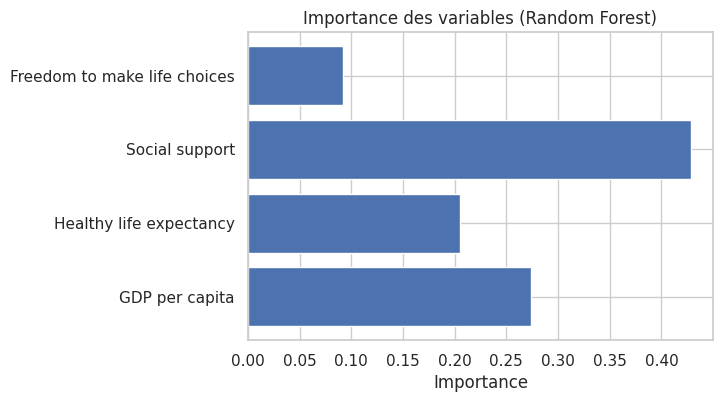

In [ ]:
import matplotlib.pyplot as plt

importances = model.feature_importances_
feature_names = X.columns

# Tracer un graphique
plt.figure(figsize=(6, 4))
plt.barh(feature_names, importances)
plt.xlabel("Importance")
plt.title("Importance des variables (Random Forest)")
plt.grid(True)
plt.show()


#GradientBoostingRegressor

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Charger le dataset prétraité
df3 = pd.read_csv("/content/sample_data/preprocessed_dataset.csv")

# 2. Séparer X (features) et y (target)
X = df3.drop(columns=["Score"])
y = df3["Score"]

# 3. Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Initialiser et entraîner le modèle
model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
model.fit(X_train, y_train)

# 5. Prédictions
y_pred = model.predict(X_test)

# 6. Évaluation
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("📉 Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("📈 R2 Score:", r2)
print(coefficients)

📉 Mean Squared Error (MSE): 0.2063623904699172
Root Mean Squared Error (RMSE): 0.5172388690774482
📈 R2 Score: 0.8317883310997788
GDP per capita                  0.953698
Social support                  1.056461
Healthy life expectancy         0.935050
Freedom to make life choices    1.398297
Generosity                      0.770283
Perceptions of corruption       0.924855
dtype: float64


#Ridge

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

# 1. Charger les données
df3 = pd.read_csv("/content/sample_data/preprocessed_dataset.csv")

# 2. Séparer X et y
X = df3.drop(columns=["Score"])
y = df3["Score"]

# 3. Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Entraîner le modèle Ridge
model = Ridge(alpha=1.0)  # alpha = force de régularisation
model.fit(X_train, y_train)

# 5. Prédiction
y_pred = model.predict(X_test)

# 6. Évaluation
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("📉 Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("📈 R2 Score:", r2)
print(coefficients)

📉 Mean Squared Error (MSE): 0.3080216913977324
Root Mean Squared Error (RMSE): 0.5172388690774482
📈 R2 Score: 0.7489230346212986
GDP per capita                  0.953698
Social support                  1.056461
Healthy life expectancy         0.935050
Freedom to make life choices    1.398297
Generosity                      0.770283
Perceptions of corruption       0.924855
dtype: float64


<ipython-input-218-19cc78ff12d8>:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=r2_scores, y=modeles, palette="viridis")


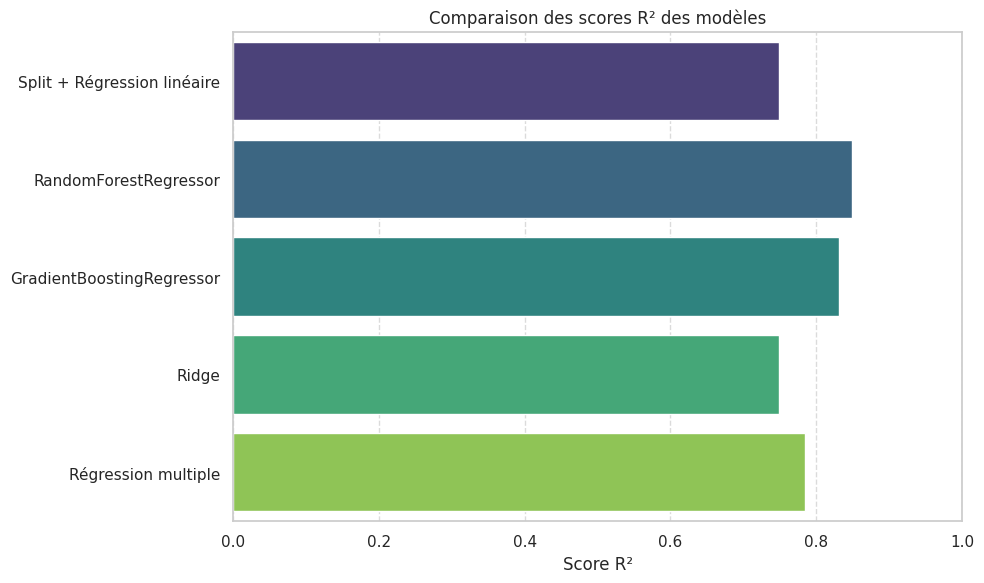

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Données des modèles
modeles = [
    "Split + Régression linéaire",
    "RandomForestRegressor",
    "GradientBoostingRegressor",
    "Ridge",
    "Régression multiple"
]
r2_scores = [
    0.7487,
    0.8492,
    0.8318,
    0.7489,
    0.7840
]

# Créer un barplot
plt.figure(figsize=(10, 6))
sns.barplot(x=r2_scores, y=modeles, palette="viridis")
plt.xlabel("Score R²")
plt.title("Comparaison des scores R² des modèles")
plt.xlim(0, 1)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


#Clustering
##K-Means
Data preparation

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# Charger les données
df3 = pd.read_csv("/content/sample_data/dataset_modifie.csv")

# Sélectionner les variables explicatives
X = df3.drop(columns=['Score'])  # pas de y ici !

# Facultatif : vérifier que les données sont bien normalisées
X.head()


,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Score_Group
0,1.340,1.587,0.986,0.596,0.153,0.393,HIGH
1,1.305,1.592,0.874,0.681,0.202,0.393,HIGH
2,1.383,1.573,0.996,0.592,0.252,0.410,HIGH
3,1.456,1.582,0.861,0.686,0.286,0.340,HIGH
4,1.351,1.590,0.868,0.683,0.284,0.408,HIGH


Finding the correct number of clusters (k) with the elbow method

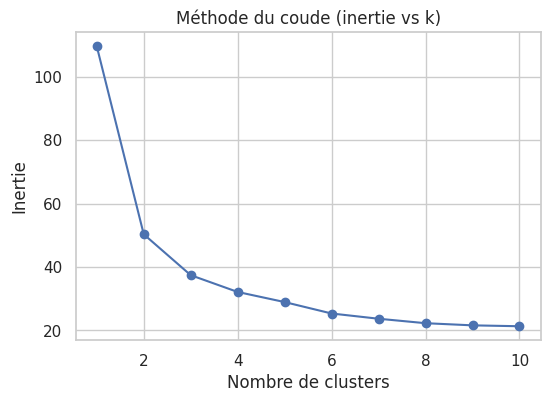

In [ ]:
inertia = []
# Garder seulement les colonnes numériques
X = df.select_dtypes(include='number').drop(columns=['Score'])


# Tester différents k (de 1 à 10)
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

# Tracer la courbe
plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), inertia, marker='o')
plt.title("Méthode du coude (inertie vs k)")
plt.xlabel("Nombre de clusters")
plt.ylabel("Inertie")
plt.grid(True)
plt.show()


Apply clustering with K optimal

In [ ]:
# Supposons que le coude est à k = 3
k_optimal = 3
kmeans = KMeans(n_clusters=k_optimal, random_state=42)
clusters = kmeans.fit_predict(X)

# Ajouter les clusters au dataset
df['Cluster'] = clusters


Visualize clusters (with 2D PCA)

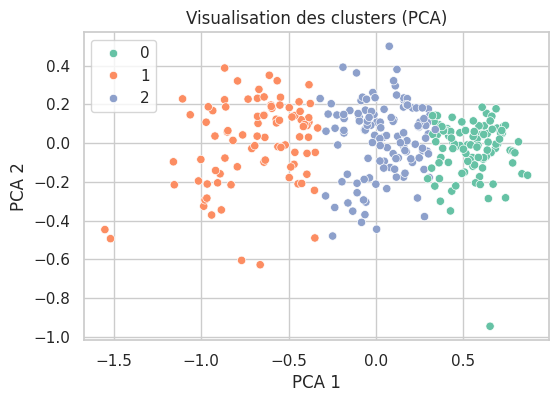

In [ ]:
from sklearn.decomposition import PCA

# Réduire à 2 dimensions pour visualiser
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(6, 4))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters, palette="Set2")
plt.title("Visualisation des clusters (PCA)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.grid(True)
plt.show()


Interpretation of clusters

1) Number of elements per cluster

In [ ]:
print(df['Cluster'].value_counts())


Cluster
2    125
0     99
1     88
Name: count, dtype: int64


2) Means of variables by cluster

In [ ]:
cluster_summary = df.groupby('Cluster').mean(numeric_only=True)
print(cluster_summary)


            Score  GDP per capita  Social support  Healthy life expectancy  \
Cluster                                                                      
0        6.539768        1.321889        1.450141                 0.898677   
1        4.192568        0.398375        0.868523                 0.350466   
2        5.326136        0.914760        1.262768                 0.692112   

         Freedom to make life choices  Generosity  Perceptions of corruption  
Cluster                                                                       
0                            0.503727    0.199535                   0.169569  
1                            0.340932    0.199193                   0.097659  
2                            0.418184    0.158320                   0.074752  
